# 阶段2：专题SQL与可比复核

本Notebook为已验收SQL结果的可复现伴随材料，保留实际执行输出与图。完整初步发现见本次结果目录的初步发现.md。

## tl;dr

总体15日记录核销率为6.1137%；分组差异对月份、商家与券方案结构敏感。可比复核必须同时查看共同覆盖率，尤其不能把窄覆盖的券方案反转推广到总体。未做因果或显著性检验。

## Context & Methods

线下成熟领券2016-01-01至06-15，消费观察至06-30，保留重复；核销0—15日含两端。6月为部分月。记录率与独立用户占比分开计算。

### Key Assumptions

Distance只使用原编码，unknown保留。小样本提示为领券<100；共同范围比较提供两组每层至少1条与至少30条两种口径。标准化使用共同层两侧领券量之和为同一权重，不证明因果，也未生成独立记录假设下的区间。来源SQL在项目o2o_work/sql，结果与指纹在manifest.json。

## Data

执行本Notebook前先运行run.sh stage2生成所需CSV。路径按当前Notebook所在项目定位；结果目录明确锁定到本次运行，不从其他结果目录拼接。

In [1]:
from pathlib import Path
import csv,json
import matplotlib
matplotlib.use('module://matplotlib_inline.backend_inline')
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from IPython.display import display,Markdown
WORK = next(p for p in [Path.cwd()/'o2o_work',Path.cwd(),*Path.cwd().parents] if (p/'config/analysis.json').exists() and (p/'sql/01_overview.sql').exists())
assert (WORK / 'config/analysis.json').exists(), '请从o2o_work或o2o_work/notebooks运行'
RESULT = WORK / 'results/stage2/runs/20261015T154046130013'
FIG = RESULT / 'figures'
FIG.mkdir(exist_ok=True)
manifest = json.loads((RESULT/'manifest.json').read_text())
assert manifest['receipt_window']==['2016-01-01','2016-06-15']
def load(name):
    with (RESULT/(name+'.csv')).open(encoding='utf-8',newline='') as f:
        return list(csv.DictReader(f))
def val(row,key): return float(row[key]) if row[key] not in ('',None) else float('nan')
def show_table(name,columns,limit=12):
    data=load(name)[:limit]
    labels={'receipt_records':'领券数','redeemed15_records':'核销数','redemption_rate15':'记录率','receipt_users':'领券用户','redeemed15_users':'核销用户','redemption_user_share15':'用户占比','receipt_month':'领券月份','distance_group':'距离编码','merchant_count':'商家数','median_receipts':'领券中位数','q75_receipts':'领券Q75','small_sample_merchants':'小样本商家','successful_receipt_records':'成功核销数','median_wait_days':'等待中位天','mean_wait_days':'平均天数','q75_wait_days':'等待Q75天','comparison_id':'比较','support_rule':'每组每层','a_common_receipts':'A共同领券','b_common_receipts':'B共同领券','a_coverage':'A覆盖','b_coverage':'B覆盖','a_standardized_rate15':'A标准化率','b_standardized_rate15':'B标准化率'}
    def fmt(k,v):
        if not v:return '—'
        if 'rate' in k or 'share' in k or 'coverage' in k:return format(float(v),'.2%')
        if k=='support_rule':return '≥30' if '30' in v else '≥1'
        if k=='comparison_id':return {'direct_vs_threshold':'券型','20_5_vs_20_1':'20:5/20:1','100_30_vs_100_10':'100:30/100:10','distance0_vs10':'距离0/10','march_vs_january':'3月/1月','largest_merchant_vs_peers':'最大商家/其他'}.get(v,v)
        if 'records' in k or 'users' in k or 'receipts' in k or 'merchants' in k or 'merchant_count' in k:return format(float(v),',.0f')
        if 'days' in k:return format(float(v),'.2f')
        return v
    text='| '+' | '.join(labels.get(k,k) for k in columns)+' |\n|'+ '|'.join(['---']*len(columns))+'|\n'
    text+='\n'.join('| '+' | '.join(fmt(k,r[k]) for k in columns)+' |' for r in data)
    display(Markdown(text))
def style(ax):
    ax.grid(axis='y',color='#e3e5e8',linewidth=.7)
    ax.set_axisbelow(True)
    ax.spines['top'].set_visible(False);ax.spines['right'].set_visible(False)
def finish(fig,name):
    fig.tight_layout()
    fig.savefig(FIG/(name+'.png'),dpi=160,bbox_inches='tight')
    plt.show()
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'figure.facecolor':'white','axes.labelcolor':'#29313a','text.color':'#29313a'})
BLUE='#3266a8';GOLD='#c88a31'
print('Source stage1 run:',manifest['stage1_run_id'])
print('CSV input SHA256:',manifest['input']['sha256'])


Source stage1 run: 20261015T154031143321
CSV input SHA256: 85ed49fd9873abebaef01a608defed667a3a2325e5c967fa25f4e9dc4b83f986


## Results

### 1. 总体与用户粒度

01_overview.sql → overview.csv。独立用户不能跨月或跨券方案相加。

In [2]:
show_table('overview',['receipt_records','redeemed15_records','redemption_rate15','receipt_users','redeemed15_users','redemption_user_share15'])
r=load('overview')[0]
assert int(r['receipt_records'])==1053282 and int(r['redeemed15_records'])==64395

| 领券数 | 核销数 | 记录率 | 领券用户 | 核销用户 | 用户占比 |
|---|---|---|---|---|---|
| 1,053,282 | 64,395 | 6.11% | 510,698 | 40,075 | 7.85% |

### 2. 月份与同日范围

02_receipt_cohort.sql → receipt_cohort.csv、receipt_cohort_days1_15.csv。6月仅1—15日；图中同日范围比率仍以该群体全体成熟领券为分母。

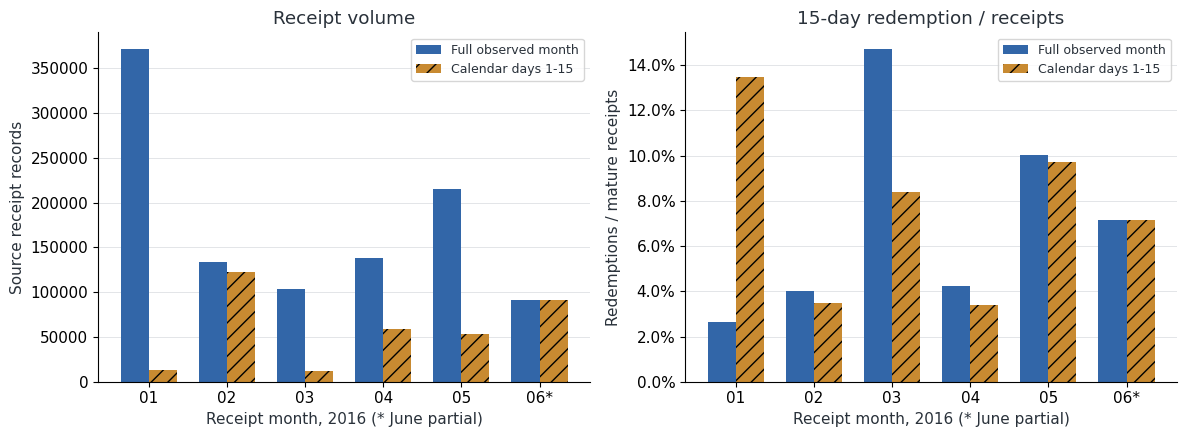

| 领券月份 | 领券数 | 核销数 | 记录率 |
|---|---|---|---|
| 2016-01 | 371,539 | 9,849 | 2.65% |
| 2016-02 | 133,433 | 5,331 | 4.00% |
| 2016-03 | 103,903 | 15,291 | 14.72% |
| 2016-04 | 138,094 | 5,833 | 4.22% |
| 2016-05 | 215,348 | 21,580 | 10.02% |
| 2016-06 | 90,965 | 6,511 | 7.16% |

In [3]:
full=load('receipt_cohort');equal=load('receipt_cohort_days1_15')
labels=[r['receipt_month'][5:]+('*' if r['receipt_month']=='2016-06' else '') for r in full]
x=list(range(len(full)))
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
for ax,key,title in [(axes[0],'receipt_records','Receipt volume'),(axes[1],'redemption_rate15','15-day redemption / receipts')]:
    ax.bar([v-.18 for v in x],[val(r,key) for r in full],width=.36,color=BLUE,label='Full observed month')
    ax.bar([v+.18 for v in x],[val(r,key) for r in equal],width=.36,color=GOLD,hatch='//',label='Calendar days 1-15')
    ax.set_xticks(x,labels);ax.set_xlabel('Receipt month, 2016 (* June partial)');ax.set_title(title);style(ax)
    ax.legend(fontsize=9)
axes[0].set_ylabel('Source receipt records');axes[1].set_ylabel('Redemptions / mature receipts');axes[1].yaxis.set_major_formatter(PercentFormatter(1))
finish(fig,'02_months')
show_table('receipt_cohort',['receipt_month','receipt_records','redeemed15_records','redemption_rate15'])


3月完整月份率最高，但同月1—15日的比较排序变化；日期和样本构成需要同时解释。

### 3. 券类型与券方案

03_coupon.sql → coupon_type_month_metrics.csv、coupon_scheme_metrics.csv。名义优惠不等于每单真实补贴，大小组均保留分子分母。

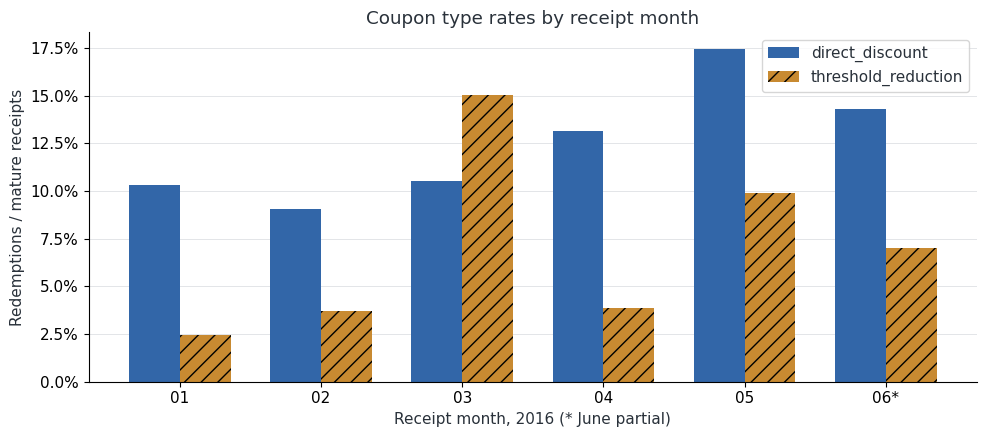

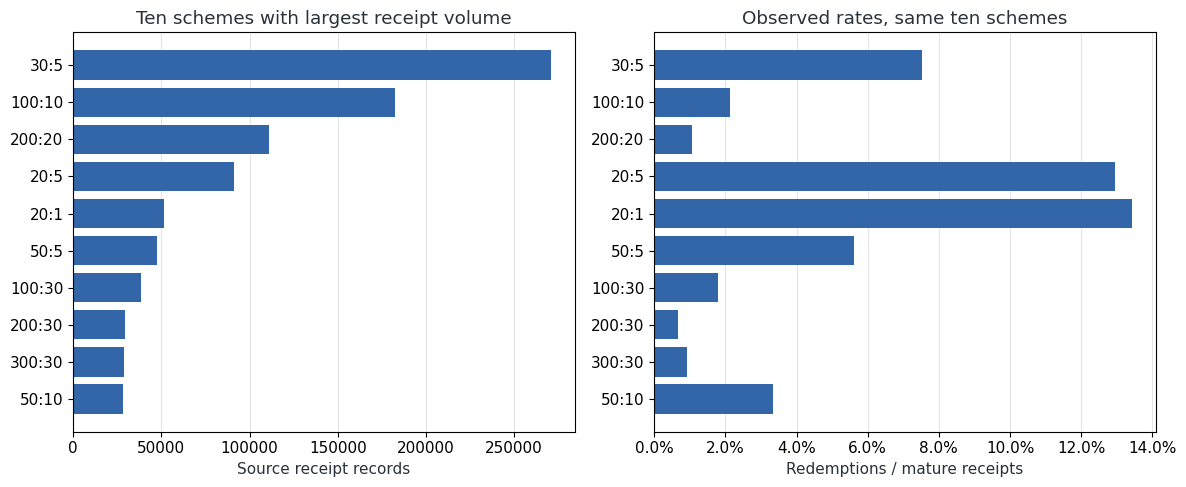

In [4]:
data=load('coupon_type_month_metrics')
months=sorted(set(r['receipt_month'] for r in data));x=list(range(len(months)))
fig,ax=plt.subplots(figsize=(10,4.5))
for typ,offset,color,hatch in [('direct_discount',-.18,BLUE,''),('threshold_reduction',.18,GOLD,'//')]:
    selected={r['receipt_month']:r for r in data if r['coupon_type']==typ}
    ax.bar([i+offset for i in x],[val(selected[m],'redemption_rate15') for m in months],width=.36,label=typ,color=color,hatch=hatch)
ax.set_xticks(x,[m[5:]+('*' if m=='2016-06' else '') for m in months]);ax.set_xlabel('Receipt month, 2016 (* June partial)');ax.set_ylabel('Redemptions / mature receipts');ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_title('Coupon type rates by receipt month');ax.legend();style(ax)
finish(fig,'03_coupon_type_months')
rows=sorted(load('coupon_scheme_metrics'),key=lambda r:int(r['receipt_records']),reverse=True)[:10]
fig,axes=plt.subplots(1,2,figsize=(12,5))
labels=[r['discount_rate'] for r in rows];y=list(range(len(rows)))
axes[0].barh(y,[val(r,'receipt_records') for r in rows],color=BLUE);axes[0].set_xlabel('Source receipt records');axes[0].set_title('Ten schemes with largest receipt volume')
axes[1].barh(y,[val(r,'redemption_rate15') for r in rows],color=BLUE);axes[1].set_xlabel('Redemptions / mature receipts');axes[1].xaxis.set_major_formatter(PercentFormatter(1));axes[1].set_title('Observed rates, same ten schemes')
for ax in axes:ax.set_yticks(y,labels);ax.invert_yaxis();ax.grid(axis='x',color='#e3e5e8');ax.set_axisbelow(True)
finish(fig,'03_coupon_schemes')


直接折扣总体较高，3月却低于满减。不同门槛、商家和用户结构使总体排名不能直接代表优惠力度效果。

### 4. 距离编码

04_distance.sql → distance_metrics.csv。编码不映射为精确公里；未知距离独立显示。

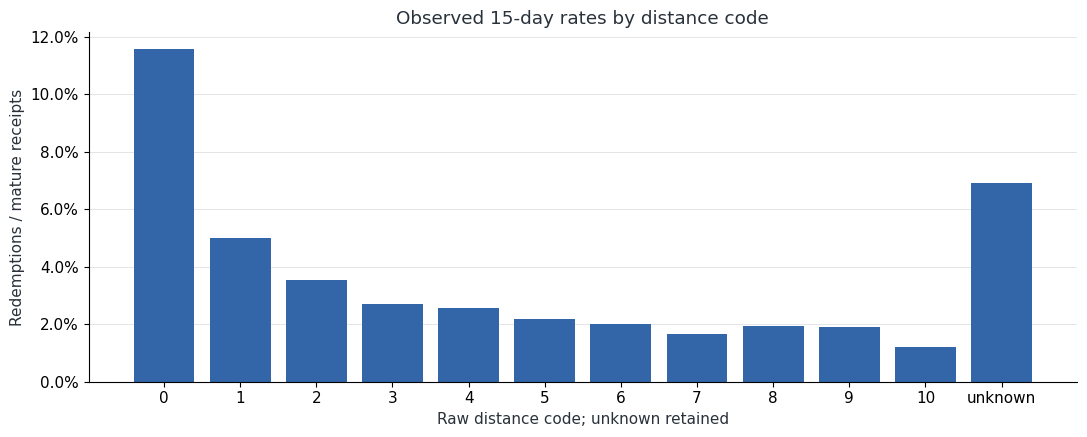

| 距离编码 | 领券数 | 核销数 | 记录率 |
|---|---|---|---|
| 0 | 348,179 | 40,281 | 11.57% |
| 1 | 143,871 | 7,212 | 5.01% |
| 2 | 81,279 | 2,868 | 3.53% |
| 3 | 54,944 | 1,488 | 2.71% |
| 4 | 40,542 | 1,041 | 2.57% |
| 5 | 31,010 | 680 | 2.19% |
| 6 | 24,658 | 494 | 2.00% |
| 7 | 19,682 | 326 | 1.66% |
| 8 | 16,404 | 319 | 1.94% |
| 9 | 13,961 | 265 | 1.90% |
| 10 | 172,749 | 2,086 | 1.21% |
| unknown | 106,003 | 7,335 | 6.92% |

In [5]:
data=load('distance_metrics')
fig,ax=plt.subplots(figsize=(11,4.5))
ax.bar([r['distance_group'] for r in data],[val(r,'redemption_rate15') for r in data],color=BLUE)
ax.set_xlabel('Raw distance code; unknown retained');ax.set_ylabel('Redemptions / mature receipts');ax.set_title('Observed 15-day rates by distance code');ax.yaxis.set_major_formatter(PercentFormatter(1));style(ax)
finish(fig,'04_distance')
show_table('distance_metrics',['distance_group','receipt_records','redeemed15_records','redemption_rate15'])


### 5. 商家规模与率

05_merchant.sql → merchant_metrics.csv。横轴为对数领券量，纵轴为记录核销率；不足100条用空心点提示，100条阈值不保证统计稳定。

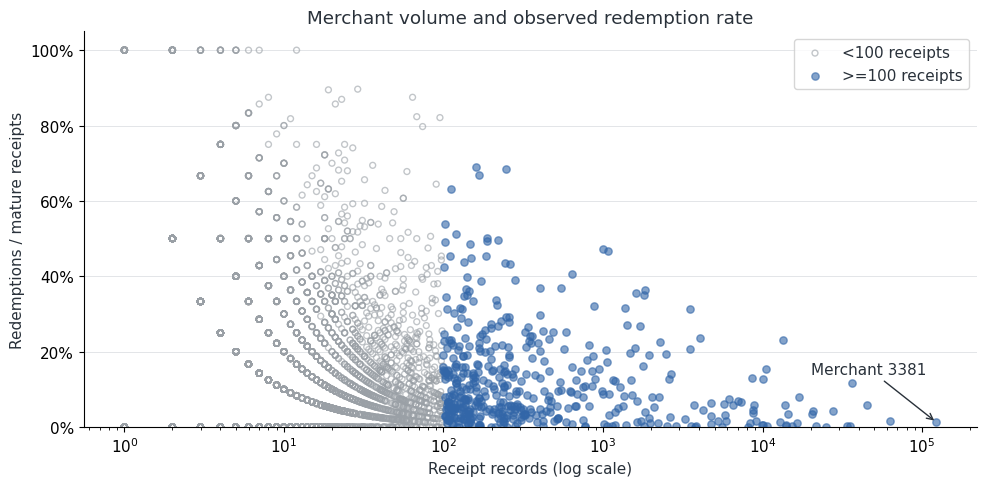

| 商家数 | 领券中位数 | 领券Q75 | 小样本商家 |
|---|---|---|---|
| 5,599 | 10 | 27 | 5,140 |

In [6]:
data=load('merchant_metrics')
fig,ax=plt.subplots(figsize=(10,5))
for small in [True,False]:
    selected=[r for r in data if (r['small_sample']=='True')==small]
    ax.scatter([val(r,'receipt_records') for r in selected],[val(r,'redemption_rate15') for r in selected],s=18 if small else 28,facecolors='none' if small else BLUE,edgecolors='#9aa0a6' if small else BLUE,alpha=.6,label='<100 receipts' if small else '>=100 receipts')
largest=max(data,key=lambda r:int(r['receipt_records']))
ax.annotate('Merchant '+largest['merchant_id'],(val(largest,'receipt_records'),val(largest,'redemption_rate15')),xytext=(-90,35),textcoords='offset points',arrowprops={'arrowstyle':'->','color':'#29313a'})
ax.set_xscale('log');ax.set_xlabel('Receipt records (log scale)');ax.set_ylabel('Redemptions / mature receipts');ax.set_ylim(0,1.05);ax.yaxis.set_major_formatter(PercentFormatter(1));ax.set_title('Merchant volume and observed redemption rate');ax.legend();style(ax)
finish(fig,'05_merchants')
show_table('merchant_distribution',['merchant_count','median_receipts','q75_receipts','small_sample_merchants'])


### 6. 核销等待时间

06_redemption_lag.sql → redemption_lag.csv。左图分母64,395条成功核销；右图分母1,053,282条成熟领券，两个比例不能互换。

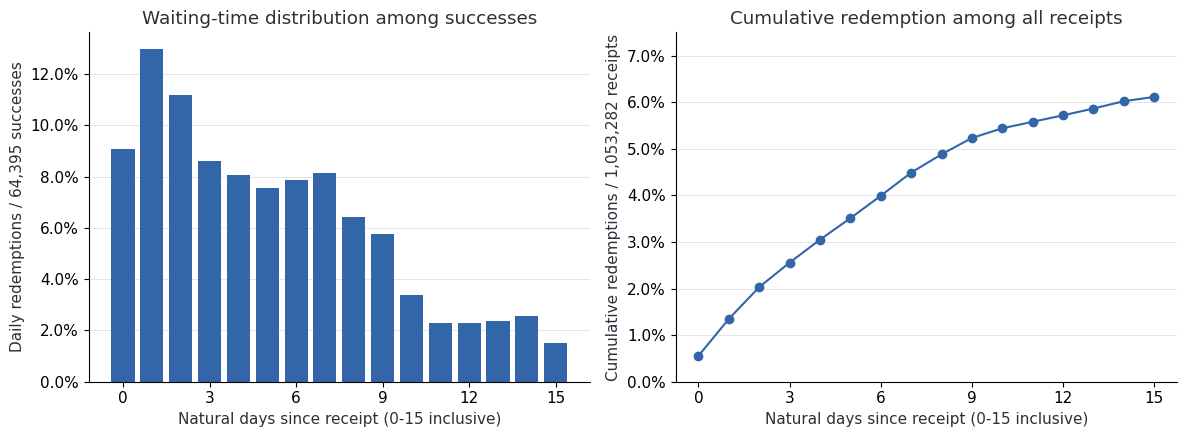

| 成功核销数 | 等待中位天 | 平均天数 | 等待Q75天 |
|---|---|---|---|
| 64,395 | 5.00 | 5.14 | 8.00 |

In [7]:
data=load('redemption_lag')
fig,axes=plt.subplots(1,2,figsize=(12,4.5))
axes[0].bar([int(r['lag_day']) for r in data],[val(r,'share_of_successful_redemptions') for r in data],color=BLUE)
axes[0].set_title('Waiting-time distribution among successes');axes[0].set_ylabel('Daily redemptions / 64,395 successes')
axes[1].plot([int(r['lag_day']) for r in data],[val(r,'cumulative_redemption_rate15') for r in data],color=BLUE,marker='o')
axes[1].set_title('Cumulative redemption among all receipts');axes[1].set_ylabel('Cumulative redemptions / 1,053,282 receipts');axes[1].set_ylim(0,.075)
for ax in axes:ax.set_xlabel('Natural days since receipt (0-15 inclusive)');ax.set_xticks(range(0,16,3));ax.yaxis.set_major_formatter(PercentFormatter(1));style(ax)
finish(fig,'06_waiting_time')
assert int(data[-1]['cumulative_redeemed15_records'])==64395
show_table('redemption_lag_summary',['successful_receipt_records','median_wait_days','mean_wait_days','q75_wait_days'])


### 7. 可比范围与共同覆盖

07_comparable_review.sql → comparison_summary.csv。standardized_numerator_receipt_equivalents为带权等效量，非实际核销条数；共同范围真实条数另列。

| 比较 | 每组每层 | A共同领券 | B共同领券 | A覆盖 | B覆盖 | A标准化率 | B标准化率 |
|---|---|---|---|---|---|---|---|
| 100:30/100:10 | ≥1 | 1,222 | 9,286 | 3.20% | 5.09% | 11.71% | 1.21% |
| 100:30/100:10 | ≥30 | 637 | 4,245 | 1.67% | 2.33% | 16.26% | 0.40% |
| 20:5/20:1 | ≥1 | 2,985 | 6,775 | 3.28% | 13.10% | 31.16% | 15.36% |
| 20:5/20:1 | ≥30 | 733 | 2,346 | 0.81% | 4.54% | 42.32% | 18.57% |
| 券型 | ≥1 | 2,134 | 42,872 | 6.41% | 4.20% | 9.33% | 3.04% |
| 券型 | ≥30 | 382 | 5,271 | 1.15% | 0.52% | 14.06% | 11.34% |
| 距离0/10 | ≥1 | 319,252 | 170,938 | 91.69% | 98.95% | 8.41% | 3.45% |
| 距离0/10 | ≥30 | 222,961 | 155,141 | 64.04% | 89.81% | 5.67% | 1.59% |
| 最大商家/其他 | ≥1 | 98,254 | 31,507 | 79.99% | 3.39% | 1.74% | 3.05% |
| 最大商家/其他 | ≥30 | 93,512 | 26,999 | 76.13% | 2.90% | 1.52% | 2.45% |
| 3月/1月 | ≥1 | 18,704 | 122,431 | 18.00% | 32.95% | 3.66% | 2.49% |
| 3月/1月 | ≥30 | 14,121 | 74,300 | 13.59% | 20.00% | 3.52% | 2.80% |

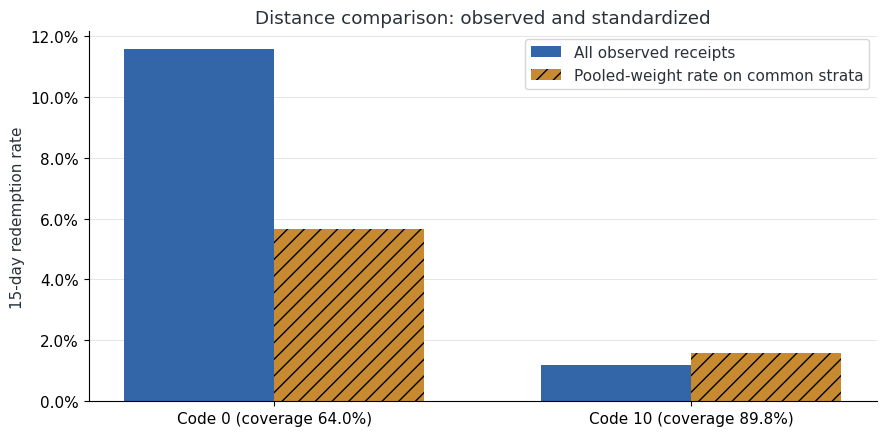

In [8]:
show_table('comparison_summary',['comparison_id','support_rule','a_common_receipts','b_common_receipts','a_coverage','b_coverage','a_standardized_rate15','b_standardized_rate15'],limit=12)
r=next(r for r in load('comparison_summary') if r['comparison_id']=='distance0_vs10' and r['support_rule']=='common_min30_each')
fig,ax=plt.subplots(figsize=(9,4.5))
ax.bar([-.18,.82],[val(r,'a_all_rate15'),val(r,'b_all_rate15')],width=.36,color=BLUE,label='All observed receipts')
ax.bar([.18,1.18],[val(r,'a_standardized_rate15'),val(r,'b_standardized_rate15')],width=.36,color=GOLD,hatch='//',label='Pooled-weight rate on common strata')
ax.set_xticks([0,1],['Code 0 (coverage '+format(val(r,'a_coverage'),'.1%')+')','Code 10 (coverage '+format(val(r,'b_coverage'),'.1%')+')'])
ax.set_ylabel('15-day redemption rate');ax.set_title('Distance comparison: observed and standardized');ax.yaxis.set_major_formatter(PercentFormatter(1));ax.legend();style(ax)
finish(fig,'07_distance_review')


## Takeaways

结果支持进一步检查活动日期、券和商家构成。距离编码0/10的方向在同月份、同商家、同券方案下仍保留；券方案比较方向可反转且覆盖很窄，不能写成优惠力度提升效果。最大领券商家的低总体率应先做结构诊断。等待时间可形成实验问题，当前没有提醒干预或随机对照。完整数字与限制见初步发现.md。

In [9]:
print('Companion notebook checks passed. Outputs retained; raw debug dumps omitted.')

Companion notebook checks passed. Outputs retained; raw debug dumps omitted.
